# Exploración de los matches MOP–DP2

Este notebook reutiliza las tablas ya generadas, sin volver a consultar DP2 ni MOP. Permite analizar targets por año derivado del nombre, origen, estado de cobertura DP2, banda y magnitudes disponibles.

La tabla MOP descargada todavía no contiene necesariamente t0, tE, magnitud de baseline ni estado activo/descartado; esos campos se incorporarán cuando exista la tabla MOP enriquecida.

In [11]:
from pathlib import Path
import sys, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'target_selection' / 'cache_paths.py').exists()), None)
if PROJECT_ROOT is None: raise RuntimeError('No se encontró la raíz del repositorio.')
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
from target_selection.cache_paths import OUTPUT_ROOT
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0,str(PROJECT_ROOT))
OUT=OUTPUT_ROOT/'mop_dp2_all'/'dp2'
TABLES=OUT/'tables'
EXPLORATION=OUT/'exploration'
EXPLORATION.mkdir(parents=True,exist_ok=True)
BANDS=tuple('ugrizy')
print('Entrada:',OUT)

Entrada: /home/karennowo/target_selection/outputs/mop_dp2_all/dp2


## 1. Cargar la tabla principal

`dp2_coadd_quality.csv` contiene una fila por target con coordenadas, visitas, coadds y banderas de métricas/píxeles.

In [12]:
quality_path=TABLES/'dp2_coadd_quality.csv'
if not quality_path.exists(): raise FileNotFoundError(f'No existe {quality_path}. Ejecutá primero el notebook 01.')
catalog=pd.read_csv(quality_path,low_memory=False)
catalog=catalog.loc[:,~catalog.columns.astype(str).str.startswith('Unnamed:')].copy()
catalog['target_id']=catalog['target_id'].astype(str)
catalog['ra_deg']=pd.to_numeric(catalog['ra_deg'],errors='coerce')
catalog['dec_deg']=pd.to_numeric(catalog['dec_deg'],errors='coerce')
print(f'Targets cargados: {len(catalog):,}')
display(catalog[['target_id','ra_deg','dec_deg','has_valid_visit_any','has_coadd','has_valid_coadd_any']].head())

Targets cargados: 6,444


,target_id,ra_deg,dec_deg,has_valid_visit_any,has_coadd,has_valid_coadd_any
0,Gaia19bnd,336.450100,25.419670,False,False,False
1,ZTF26abbbguw,289.630895,15.315267,False,False,False
2,AT2026aabo,11.226083,41.552913,False,False,False
3,ZTF26abrjfga,271.014203,-8.466024,False,False,False
4,ZTF26abnuqyj,114.840879,34.412027,False,False,False


## 2. Crear variables de año, origen y estado DP2

El año se extrae del nombre (`OGLE-2026`, `MOA-2023`, etc.); no se interpreta como un campo físico MOP.

In [13]:
catalog['event_year']=pd.to_numeric(catalog['target_id'].str.extract(r'(?<!\d)(20\d{2})(?!\d)',expand=False),errors='coerce').astype('Int64')
catalog['event_source']=catalog['target_id'].str.extract(r'^([A-Za-z]+)',expand=False).fillna('Other').str.upper()
for col in ['has_valid_visit_any','has_coadd','has_valid_metrics_any','has_valid_pixels_any','has_valid_coadd_any']:
    catalog[col]=catalog[col].fillna(False).astype(bool)
catalog['dp2_status']=np.select([catalog['has_valid_coadd_any'],catalog['has_valid_pixels_any'],catalog['has_valid_metrics_any'],catalog['has_coadd'],catalog['has_valid_visit_any']],['valid_coadd','valid_pixels_only','valid_metrics_only','coadd_found_only','visits_only'],default='no_visit_or_coadd')
display(catalog['dp2_status'].value_counts().rename_axis('dp2_status').to_frame('targets'))

,targets
dp2_status,
valid_coadd,4681
no_visit_or_coadd,1260
visits_only,453
valid_pixels_only,42
valid_metrics_only,4
coadd_found_only,4


In [22]:
catalog.columns.tolist()

['target_id',
 'Name',
 'Target Type',
 'Right Ascension',
 'Declination',
 'mop_link',
 'Target',
 'ra_deg',
 'dec_deg',
 'RA_deg',
 'Dec_deg',
 'coordinates_valid',
 'n_images_g',
 'n_images_i',
 'n_images_r',
 'n_images_u',
 'n_images_y',
 'n_images_z',
 'visit_seeing_mean_arcsec_g',
 'visit_seeing_mean_arcsec_i',
 'visit_seeing_mean_arcsec_r',
 'visit_seeing_mean_arcsec_u',
 'visit_seeing_mean_arcsec_y',
 'visit_seeing_mean_arcsec_z',
 'visit_seeing_best_arcsec_g',
 'visit_seeing_best_arcsec_i',
 'visit_seeing_best_arcsec_r',
 'visit_seeing_best_arcsec_u',
 'visit_seeing_best_arcsec_y',
 'visit_seeing_best_arcsec_z',
 'visit_maglim_mean_g',
 'visit_maglim_mean_i',
 'visit_maglim_mean_r',
 'visit_maglim_mean_u',
 'visit_maglim_mean_y',
 'visit_maglim_mean_z',
 'visit_maglim_best_g',
 'visit_maglim_best_i',
 'visit_maglim_best_r',
 'visit_maglim_best_u',
 'visit_maglim_best_y',
 'visit_maglim_best_z',
 'visit_exptime_mean_s_g',
 'visit_exptime_mean_s_i',
 'visit_exptime_mean_s_r',
 '

In [14]:
catalog["coverage_status"] = np.select(
  [
      catalog["has_coadd"] & catalog["has_valid_visit_any"],
      catalog["has_coadd"] & ~catalog["has_valid_visit_any"],
      ~catalog["has_coadd"] & catalog["has_valid_visit_any"],
  ],
  [
      "coadd_and_visits",
      "coadd_only",
      "visits_only",
  ],
  default="neither",
)

display(
  catalog["coverage_status"]
  .value_counts()
  .rename_axis("coverage_status")
  .to_frame("targets")
)

,targets
coverage_status,
coadd_and_visits,4731
neither,1260
visits_only,453


## 3. Agregar match DIA y magnitudes DP2

Un target tiene match DIA si el CSV guardado contiene al menos una fila `measurement_status == measured`. Las magnitudes DP2 se resumen sólo para esos puntos medidos.

In [15]:
dia_path=TABLES/'dp2_dia_forced_photometry.csv'
if dia_path.exists():
    dia=pd.read_csv(dia_path,low_memory=False)
    dia['target_id']=dia['target_id'].astype(str) if 'target_id' in dia.columns else dia['Target'].astype(str)
    dia['is_measured']=dia.get('measurement_status','measured').astype(str).eq('measured')
    dia_summary=dia.groupby('target_id').agg(dp2_dia_match=('is_measured','any'),dp2_n_forced_points=('is_measured','sum'),dp2_n_bands=('band','nunique'),dp2_magnitude_median=('magnitude','median'),dp2_magnitude_brightest=('magnitude','min')).reset_index()
else:
    dia_summary=pd.DataFrame(columns=['target_id','dp2_dia_match','dp2_n_forced_points','dp2_n_bands','dp2_magnitude_median','dp2_magnitude_brightest'])
catalog=catalog.merge(dia_summary,on='target_id',how='left')
catalog['dp2_dia_match']=catalog['dp2_dia_match'].fillna(False).astype(bool)
catalog['dp2_n_forced_points']=catalog['dp2_n_forced_points'].fillna(0).astype(int)
print('Targets con match DIA:',int(catalog['dp2_dia_match'].sum()))
display(catalog[['target_id','dp2_dia_match','dp2_n_forced_points','dp2_n_bands']].head())

Targets con match DIA: 504


,target_id,dp2_dia_match,dp2_n_forced_points,dp2_n_bands
0,Gaia19bnd,False,0,0
1,ZTF26abbbguw,False,0,0
2,AT2026aabo,False,0,0
3,ZTF26abrjfga,False,0,0
4,ZTF26abnuqyj,False,0,0


## 4. Magnitudes MOP disponibles en cache

La tabla de targets MOP no tiene todavía una magnitud global para todos los eventos. Esta celda recorre sólo los CSV MOP ya descargados y calcula mediana, máximo brillo y cantidad de puntos.

In [16]:
mop_cache=OUT.parent/'cache'/'mop_photometry'
mop_rows=[]
for path in sorted(mop_cache.glob('*.csv')):
    phot=pd.read_csv(path,low_memory=False)
    if phot.empty or 'Magnitude' not in phot.columns: continue
    mags=pd.to_numeric(phot['Magnitude'],errors='coerce').dropna()
    if mags.empty: continue
    mop_rows.append({'target_id':path.stem,'mop_photometry_cached':True,'mop_n_points':len(mags),'mop_magnitude_median':mags.median(),'mop_magnitude_brightest':mags.min(),'mop_magnitude_faintest':mags.max()})
mop_summary=pd.DataFrame(mop_rows)
if mop_summary.empty: mop_summary=pd.DataFrame(columns=['target_id','mop_photometry_cached','mop_n_points','mop_magnitude_median','mop_magnitude_brightest','mop_magnitude_faintest'])
catalog=catalog.merge(mop_summary,on='target_id',how='left')
catalog['mop_photometry_cached']=catalog['mop_photometry_cached'].fillna(False).astype(bool)
catalog['mop_n_points']=catalog['mop_n_points'].fillna(0).astype(int)
print('Targets con fotometría MOP cacheada:',int(catalog.mop_photometry_cached.sum()))
display(catalog.loc[catalog.mop_photometry_cached,['target_id','mop_n_points','mop_magnitude_median']].head())

Targets con fotometría MOP cacheada: 25


/tmp/ipykernel_1645/2122536025.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  catalog['mop_photometry_cached']=catalog['mop_photometry_cached'].fillna(False).astype(bool)


,target_id,mop_n_points,mop_magnitude_median
5,ZTF26aawmspr,2921,17.897228
6,OGLE-2026-BLG-0888,1093,17.372028
10,ZTF26aauqxam,1293,18.418000
13,LSST_313761042268160096,92,23.601297
15,ZTF26aazuuhy,759,17.813000


## 5. Resúmenes y archivos de salida

In [17]:
year_summary=catalog.groupby('event_year',dropna=False).agg(targets=('target_id','nunique'),visits=('has_valid_visit_any','sum'),coadds=('has_coadd','sum'),valid_metrics=('has_valid_metrics_any','sum'),valid_pixels=('has_valid_pixels_any','sum'),valid_coadds=('has_valid_coadd_any','sum'),dia_matches=('dp2_dia_match','sum')).reset_index()
source_summary=catalog.groupby('event_source').agg(targets=('target_id','nunique'),visits=('has_valid_visit_any','sum'),valid_coadds=('has_valid_coadd_any','sum'),dia_matches=('dp2_dia_match','sum')).sort_values('targets',ascending=False).reset_index()
status_summary=catalog['dp2_status'].value_counts().rename_axis('dp2_status').reset_index(name='targets')
band_rows=[]
for band in BANDS:
    band_rows.append({'band':band,'targets_with_visits':int(catalog[f'has_valid_visit_{band}'].fillna(False).astype(bool).sum()),'targets_with_coadd':int(catalog[f'has_coadd_{band}'].fillna(False).astype(bool).sum()),'targets_with_valid_metrics':int(catalog[f'has_valid_metrics_{band}'].fillna(False).astype(bool).sum()),'targets_with_valid_pixels':int(catalog[f'has_valid_pixels_{band}'].fillna(False).astype(bool).sum()),'targets_with_valid_coadd':int(catalog[f'has_valid_coadd_{band}'].fillna(False).astype(bool).sum())})
band_summary=pd.DataFrame(band_rows)
display(year_summary); display(source_summary.head(20)); display(status_summary); display(band_summary)
catalog.to_csv(EXPLORATION/'mop_dp2_exploration_catalog.csv',index=False)
year_summary.to_csv(EXPLORATION/'counts_by_year.csv',index=False)
source_summary.to_csv(EXPLORATION/'counts_by_source.csv',index=False)
status_summary.to_csv(EXPLORATION/'counts_by_dp2_status.csv',index=False)
band_summary.to_csv(EXPLORATION/'counts_by_band.csv',index=False)

,event_year,targets,visits,coadds,valid_metrics,valid_pixels,valid_coadds,dia_matches
0,2023,1616,1527,1513,1507,1511,1505,104
1,2024,1523,1455,1444,1425,1441,1423,77
2,2025,1491,1416,1410,1396,1409,1395,200
3,2026,160,153,151,151,150,150,21
4,<NA>,1654,633,213,208,212,208,102


,event_source,targets,visits,valid_coadds,dia_matches
0,OGLE,4143,3908,3836,394
1,GAIA,1627,619,196,95
2,MOA,642,642,637,8
3,ZTF,23,10,10,6
4,AT,5,1,0,0
5,ASASSN,1,1,1,0
6,ESO,1,1,0,0
7,LSST,1,1,1,1
8,LUHMAN,1,1,0,0


,dp2_status,targets
0,valid_coadd,4681
1,no_visit_or_coadd,1260
2,visits_only,453
3,valid_pixels_only,42
4,valid_metrics_only,4
5,coadd_found_only,4


,band,targets_with_visits,targets_with_coadd,targets_with_valid_metrics,targets_with_valid_pixels,targets_with_valid_coadd
0,u,4310,3997,3461,3936,3455
1,g,4687,4252,3782,4176,3761
2,r,4705,4588,3969,4495,3938
3,i,5008,4663,4137,4492,4027
4,z,4824,3308,2489,3154,2472
5,y,4274,3822,2902,3551,2763


## 6. Gráficos por año, estado y magnitud

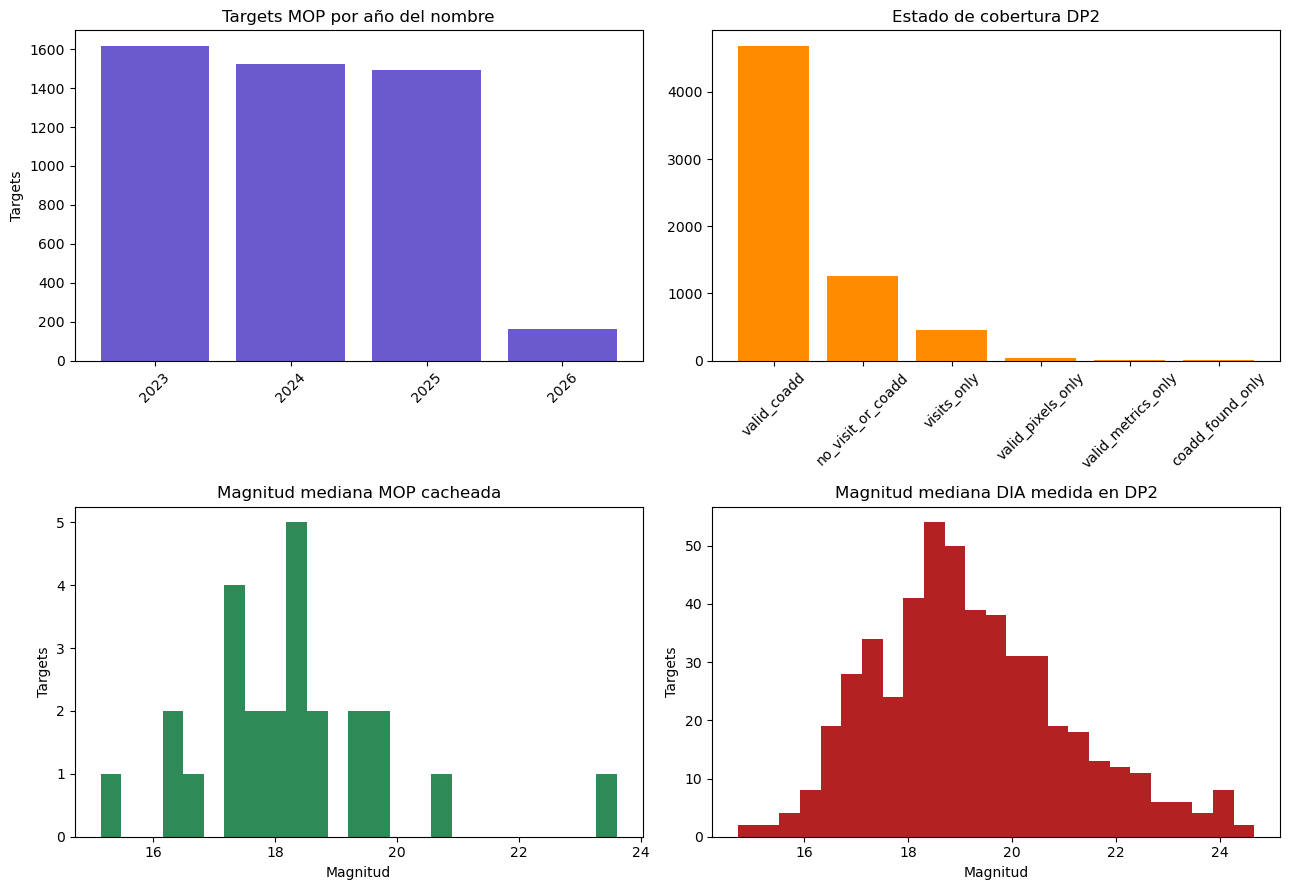

In [18]:
fig,axes=plt.subplots(2,2,figsize=(13,9))
year_plot=year_summary.dropna(subset=['event_year'])
axes[0,0].bar(year_plot['event_year'].astype(int).astype(str),year_plot['targets'],color='slateblue'); axes[0,0].set_title('Targets MOP por año del nombre'); axes[0,0].set_ylabel('Targets'); axes[0,0].tick_params(axis='x',rotation=45)
axes[0,1].bar(status_summary['dp2_status'],status_summary['targets'],color='darkorange'); axes[0,1].set_title('Estado de cobertura DP2'); axes[0,1].tick_params(axis='x',rotation=45)
axes[1,0].hist(catalog.loc[catalog.mop_photometry_cached,'mop_magnitude_median'].dropna(),bins=25,color='seagreen'); axes[1,0].set_title('Magnitud mediana MOP cacheada'); axes[1,0].set_xlabel('Magnitud'); axes[1,0].set_ylabel('Targets')
axes[1,1].hist(catalog.loc[catalog.dp2_dia_match,'dp2_magnitude_median'].dropna(),bins=25,color='firebrick'); axes[1,1].set_title('Magnitud mediana DIA medida en DP2'); axes[1,1].set_xlabel('Magnitud'); axes[1,1].set_ylabel('Targets')
fig.tight_layout(); fig.savefig(EXPLORATION/'mop_dp2_distributions.png',dpi=180,bbox_inches='tight'); plt.show()

## 7. Filtros para crear listas de targets

Cambiar estos valores permite seleccionar por año, magnitud MOP, cantidad de puntos DIA, coadd válido o match DIA.

In [19]:
YEAR=None
MAX_MOP_MAG=None
MIN_DP2_POINTS=0
ONLY_VALID_COADD=False
ONLY_DIA_MATCH=False
selection=catalog.copy()
if YEAR is not None: selection=selection.loc[selection.event_year.eq(YEAR)]
if MAX_MOP_MAG is not None: selection=selection.loc[selection.mop_magnitude_median.le(MAX_MOP_MAG)]
selection=selection.loc[selection.dp2_n_forced_points.ge(MIN_DP2_POINTS)]
if ONLY_VALID_COADD: selection=selection.loc[selection.has_valid_coadd_any]
if ONLY_DIA_MATCH: selection=selection.loc[selection.dp2_dia_match]
selection.to_csv(EXPLORATION/'selected_targets.csv',index=False)
print('Seleccionados:',len(selection))
display(selection[['target_id','event_year','event_source','dp2_status','dp2_dia_match','mop_magnitude_median','dp2_magnitude_median']].head(30))

Seleccionados: 6444


,target_id,event_year,event_source,dp2_status,dp2_dia_match,mop_magnitude_median,dp2_magnitude_median
0,Gaia19bnd,<NA>,GAIA,no_visit_or_coadd,False,NaN,NaN
1,ZTF26abbbguw,<NA>,ZTF,no_visit_or_coadd,False,NaN,NaN
2,AT2026aabo,2026,AT,no_visit_or_coadd,False,NaN,NaN
3,ZTF26abrjfga,<NA>,ZTF,no_visit_or_coadd,False,NaN,NaN
4,ZTF26abnuqyj,<NA>,ZTF,no_visit_or_coadd,False,NaN,NaN
5,ZTF26aawmspr,<NA>,ZTF,valid_coadd,False,17.897228,NaN
6,OGLE-2026-BLG-0888,2026,OGLE,valid_coadd,True,17.372028,17.719085
7,ZTF26abofflw,<NA>,ZTF,no_visit_or_coadd,False,NaN,NaN
8,ZTF26abotmks,<NA>,ZTF,no_visit_or_coadd,False,NaN,NaN
9,ZTF25aahufrx,<NA>,ZTF,no_visit_or_coadd,False,NaN,NaN
